# Thompson sampling

You can show one of five ads each round. Each has a hidden click rate. Try to find the
best ad without giving up too many clicks while you explore. A click pays 1; a miss pays 0.

## Load the click log

Each row is a round, and each column is an ad. The log has hypothetical outcomes for
all five ads, so each policy can replay the same rounds. To stay fair, the simulator
chooses an ad first and then reads only that ad's cell. No policy learns from the other cells.

In [1]:
import numpy as np

url = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/ad_clicks.csv"
clicks = np.loadtxt(url, delimiter=",", skiprows=1, dtype=int)
num_rounds, num_ads = clicks.shape

## Draw one possible rate per ad

Each ad starts with a flat Beta(1, 1) distribution. After seeing clicks and misses,
its distribution is Beta(1 + wins, 1 + losses). Sample once per ad and choose the
highest draw. UCB is the other learned policy: it tries each ad once, then adds an
uncertainty bonus to each observed mean instead of drawing samples.

In [2]:
thompson_rng = np.random.default_rng(2026)

def choose_thompson(t, plays, wins):
    losses = plays - wins
    samples = thompson_rng.beta(1 + wins, 1 + losses)
    return np.argmax(samples)

In [3]:
def choose_ucb(t, plays, wins):
    if t < len(plays):
        return t
    mean = wins / plays
    bonus = np.sqrt(2 * np.log(t) / plays)
    return np.argmax(mean + bonus)

## Replay and compare

Each policy starts with no observations. The random baseline ignores its scores and
picks an ad uniformly. Compare all policies on the same click log, without letting their
choices or observations affect each other.

In [4]:
random_rng = np.random.default_rng(2027)

def choose_random(t, plays, wins):
    return random_rng.integers(num_ads)

def replay(choose):
    plays = np.zeros(num_ads, dtype=int)
    wins = np.zeros_like(plays)
    chosen = np.empty(num_rounds, dtype=int)
    rewards = np.empty(num_rounds, dtype=int)
    for t in range(num_rounds):
        ad = choose(t, plays, wins)
        reward = clicks[t, ad]
        chosen[t] = ad
        rewards[t] = reward
        plays[ad] += 1
        wins[ad] += reward
    return chosen, np.r_[0, np.cumsum(rewards)]

In [5]:
results = {"Thompson": replay(choose_thompson), "UCB": replay(choose_ucb),
           "Random": replay(choose_random)}
for label, (_, cumulative) in results.items():
    print(label, cumulative[-1])

Thompson 7474
UCB 7380
Random 3832


## See it

The histogram counts how often each ad was chosen. The lines add up clicks as each
policy plays. Which ads did each learned policy favor, and how much did that pay off?

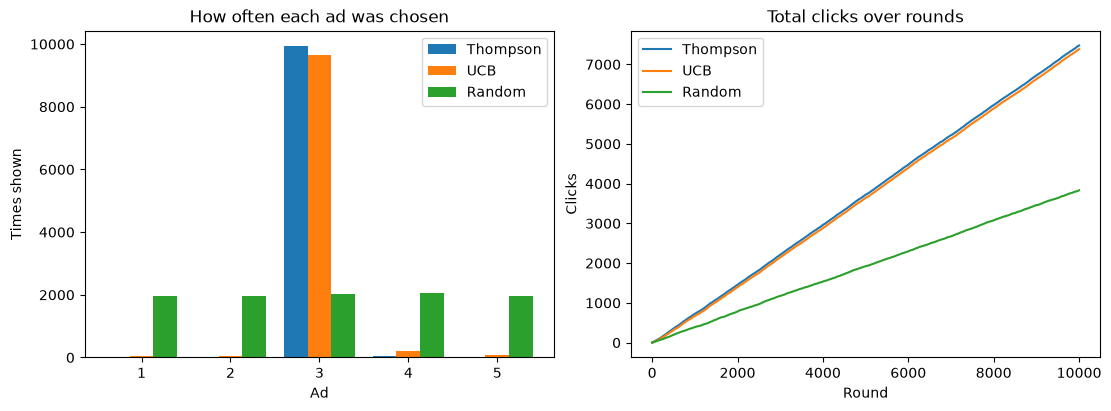

In [6]:
import matplotlib.pyplot as plt

ads = np.arange(1, num_ads + 1)
width = 0.8 / len(results)
fig, (histogram, timeline) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

for index, (label, (chosen, cumulative)) in enumerate(results.items()):
    counts = np.bincount(chosen, minlength=num_ads)
    offset = (index - (len(results) - 1) / 2) * width
    histogram.bar(ads + offset, counts, width=width, label=label)
    timeline.plot(np.arange(num_rounds + 1), cumulative, label=label)

histogram.set(title="How often each ad was chosen", xlabel="Ad", ylabel="Times shown", xticks=ads)
timeline.set(title="Total clicks over rounds", xlabel="Round", ylabel="Clicks")
histogram.legend()
timeline.legend()
plt.show()